# Coin toss simulation

Python version of `unfair_coin_toss.m`. Each trial is a random number in [0, 1); it is a head if it is
below `p_heads`. Watch the percentage of heads settle towards `p_heads` as the number of trials grows.
Change `p_heads` to simulate an unfair coin.

**Simulate the tosses.** `rng.random(n) < p_heads` gives `True` (a head) with probability `p_heads`. The running totals give the count and the percentage of heads after each toss.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)   # fixed seed = same results each run; remove the 1 for new results

p_heads = 0.5      # probability of heads
no_trials = 500    # number of tosses

trials = rng.random(no_trials) < p_heads
n = np.arange(1, no_trials + 1)

no_heads = np.cumsum(trials)
no_tails = n - no_heads
per_heads = no_heads / n * 100
per_tails = no_tails / n * 100
print(f"After {no_trials} tosses: {no_heads[-1]} heads ({per_heads[-1]:.1f}%), {no_tails[-1]} tails")

After 500 tosses: 259 heads (51.8%), 241 tails


**Plot the running counts and percentages.** The dashed line is the expected percentage.

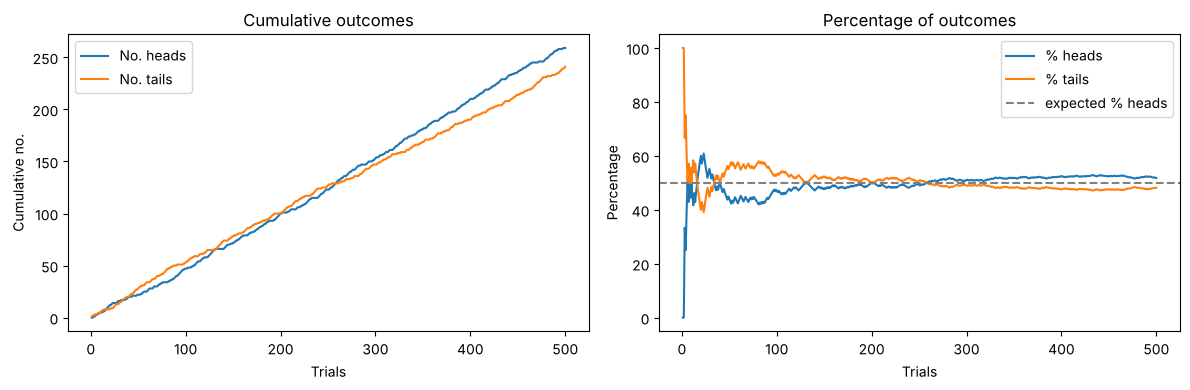

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(n, no_heads, label="No. heads")
axes[0].plot(n, no_tails, label="No. tails")
axes[0].set(xlabel="Trials", ylabel="Cumulative no.", title="Cumulative outcomes")
axes[0].legend()

axes[1].plot(n, per_heads, label="% heads")
axes[1].plot(n, per_tails, label="% tails")
axes[1].axhline(p_heads * 100, color="grey", linestyle="--", label="expected % heads")
axes[1].set(xlabel="Trials", ylabel="Percentage", title="Percentage of outcomes")
axes[1].legend()
plt.tight_layout()
plt.show()

**What to look for.** The percentage of heads swings widely for the first few dozen tosses and then settles near `p_heads`: the law of large numbers. Try `p_heads = 0.58` (the unfair coin in the Excel demo) or remove the seed.